# Volatility Dynamics 13 — Two timescales, a price martingale, and local reversion

**Experimental status:** pre-registered retrospective exploratory analysis; **not** option trading, not a signal, not confirmed research, and not a latent HSMM.

**Read first:** [`discussions/Volatility_Dynamics/030_chatgpt_vd13_price_distribution_preregistration.md`](../../discussions/Volatility_Dynamics/030_chatgpt_vd13_price_distribution_preregistration.md).

Questions:
1. Does simple 30m + 4h volatility memory improve the **conditional price-return distribution** over a zero-mean random walk with constant asset variance?
2. Does the **phase** of fast versus slow volatility improve further, beyond the two-EMA baseline?
3. Do lagged **signed returns** add conditional price mean reversion, and does conditioning that signed prediction on volatility phase add more?

No empirical result from Regime Structure or other research branches is imported. RS 06 motivates these independently tested questions but is not used to choose coefficients, event thresholds or fitted states. The shared raw history is Binance spot 5m closes, **not** Binance USD-M perpetual futures used in Regime Structure; numerical variance-ratio estimates must not be equated across sources.

**Dataset:** `DERIBIT_DATA_ROOT/history/price_5m/<ASSET>.csv.gz` through `< 2026-09-19 00:00 UTC`. History before this date has been seen in previous research, so historical test results cannot serve as pristine independent confirmation. Assets with <365 days excluded. All return targets are close-to-close on exactly consecutive 5m bars; no missing-data interpolation.

**Primary forecast:** 60-minute future price log return \(R_h=\sum_{k=1}^{h/5}r_{t+k}\), integrated realized variance \(RV_h=\sum r_{t+k}^2\), and exceedance indicator \({\bf1}\{|R_h|\ge q^{train}_{.95,|R_h|}\}\). Secondary: 15m and 240m. All future windows fully observed and cannot cross fit/validation/test date boundaries. At origin t, the return at t **is known**, but all future returns are excluded from features.

**Five nested explanations:** K (asset-specific zero-drift constant-variance normal random walk); E (zero-drift Gaussian with future variance from current plus 30m/4h EMA log-variance predictors); P (E plus nonlinear fast/slow gap and phase/slope); M (P variance plus signed 5m and 30m lag returns as conditional price mean); PM (M plus signed-return × volatility-phase interactions). Gaussian is a testable **quasi-distribution**, not a true-fat-tail assertion; extreme-tail calibration is scored explicitly.

**Train-only estimates:** UTC-hour de-clocking, variance epsilon, tail thresholds, regression coefficients, normalization, and Gaussian variance scale calibration. Fixed ridge strengths; no test-based tuning. Chronological UTC-day 60/20/20 split, 24h elapsed history at >=80% observed coverage and at least one observed return in the prior 15m. Paired all-asset day bootstrap B=1000 (default). At 60m compare E−K, P−E, M−P, PM−M on Gaussian log score, log-RV MSE, tail log loss and sign log loss. Negative paired difference means better.

Historical outcomes are always labeled `HISTORICAL_EXPLORATORY` when the adequacy gate passes (>=30 test days and >=40 unique positive-tail origin timestamps). New post-2026-10-13 history, with a freshly frozen out-of-sample protocol, is needed for confirmatory claims. **No option or gamma-scalping P&L is inferred from forecasting skill.**

## 0. Environment and frozen registration

In [1]:
from pathlib import Path
import sys, os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT/'src'/'data_engineering').exists():
    ROOT = ROOT.parent
assert (ROOT/'src'/'data_engineering').exists(), 'Open notebook within the repository'
load_dotenv(ROOT/'.env')
SRC = ROOT/'src'
if str(SRC) not in sys.path: sys.path.insert(0,str(SRC))
from data_engineering.modeling import volatility_price_distribution as vd

DATA_ROOT=Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
HIST_DIR=Path(os.getenv('VD13_HISTORY_DIR',str(DATA_ROOT/'history'/'price_5m')))
ASSETS=[s.strip().upper() for s in os.getenv('VD13_ASSETS','AVAX,BTC,ETH,HYPE,SOL,TRX,XRP').split(',') if s.strip()]
BOOT=int(os.getenv('VD13_BOOT','1000'))
OUT=ROOT/'notebooks'/'Volatility_Dynamics'/'13'
OUT.mkdir(parents=True,exist_ok=True)
t0=time.time()
print(json.dumps(vd.registration(),indent=2))
print('Historical source:',HIST_DIR,'| assets:',ASSETS,'| day-bootstrap:',BOOT)

{
  "end_exclusive": "2026-09-19 00:00:00+00:00",
  "horizons": [
    15,
    60,
    240
  ],
  "primary_horizon": 60,
  "fast_half_life_min": 30,
  "slow_half_life_min": 240,
  "minimum_previous_bars": 288,
  "previous_coverage_min": 0.8,
  "ridge_var": 0.02,
  "ridge_mean": 0.1,
  "tail_quantile": 0.95,
  "split_train": 0.6,
  "split_valid": 0.2,
  "min_test_days": 30,
  "min_unique_tail_times": 40,
  "historical_sample_is_exploratory": true,
  "version": "VD13-0.1.0",
  "source": "shared history/price_5m raw close files",
  "not_an_options_backtest": true,
  "no_tradability_claim": true
}
Historical source: D:\MarketData\Deribit\history\price_5m | assets: ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP'] | day-bootstrap: 1000


## 1. Independent raw 5m panel, train-only features and exact future labels

In [2]:
raw, excluded = vd.load_returns(HIST_DIR,ASSETS)
print('Assets excluded:',excluded)
print('Raw rows:',len(raw),'assets:',sorted(raw.underlying.unique()))
panel=vd.prepare_panel(raw)
del raw
features,clock=vd.make_features(panel)
frame,thresholds=vd.add_forward_targets(panel,features)
print('Prepared in',round(time.time()-t0,1),'s; rows:',len(frame))
display(frame.groupby('split',sort=False).agg(days=('date','nunique'),
    rows=('return_5m','size'),valid_bars=('return_5m','count'),
    history_ready=('history_ok','sum'),median_history_coverage=('past_coverage','median'),
    first=('state_time','min'),last=('state_time','max')))
display(pd.DataFrame(thresholds).rename_axis('asset').sort_index())
assert frame.state_time.max() < vd.SAMPLE_END


Assets excluded: {'HYPE': '0 days, require 365'}
Raw rows: 1292538 assets: ['AVAX', 'BTC', 'ETH', 'SOL', 'TRX', 'XRP']
Prepared in 9.4 s; rows: 1292538


,days,rows,valid_bars,history_ready,median_history_coverage,first,last
split,,,,,,,
train,448,774138,774132,772410,1.0,2024-09-01 00:05:00+00:00,2025-11-22 23:55:00+00:00
valid,150,259200,259200,259200,1.0,2025-11-23 00:00:00+00:00,2026-04-21 23:55:00+00:00
test,150,259200,259200,259200,1.0,2026-04-22 00:00:00+00:00,2026-09-18 23:55:00+00:00


,15,60,240
asset,,,
AVAX,0.010058,0.020047,0.040765
BTC,0.004844,0.009763,0.020164
ETH,0.007374,0.014937,0.030629
SOL,0.008913,0.017734,0.035511
TRX,0.004563,0.009849,0.020379
XRP,0.009920,0.019390,0.038514


## 2. Complete-case forecast evaluation: five frozen models, all horizons

In [3]:
score_list=[]
pred_list=[]
for h in vd.HORIZONS:
    scores,pred=vd.fit_horizon(frame,h)
    score_list.append(scores)
    pred_list.append(pred)
    print('Horizon',h,'min:',len(pred)//5,'common test origins','(',
           scores.n_days.iloc[0],'UTC test days )')
scores=pd.concat(score_list,ignore_index=True)
display(scores[['horizon_min','model','n_origins','n_days',
                'nll','rv_log_mse','tail_logloss','tail_brier',
                'sign_logloss','tail_observed_avg','tail_forecast_avg']])
scores.to_csv(OUT/'13_scores.csv',index=False,float_format='%.8g')


Horizon 15 min: 259182 common test origins ( 150 UTC test days )
Horizon 60 min: 259128 common test origins ( 150 UTC test days )
Horizon 240 min: 258912 common test origins ( 150 UTC test days )


,horizon_min,model,n_origins,n_days,nll,rv_log_mse,tail_logloss,tail_brier,sign_logloss,tail_observed_avg,tail_forecast_avg
0,15,K_random_walk,259182,150,-4.482827,7.259199,0.099034,0.018561,0.693147,0.018474,0.038244
1,15,E_two_ema,259182,150,-4.758660,5.367544,0.095982,0.017108,0.693147,0.018474,0.011154
2,15,P_vol_phase,259182,150,-4.761606,5.357002,0.095230,0.017043,0.693147,0.018474,0.011331
3,15,M_price_reversion,259182,150,-4.758934,5.357002,0.094539,0.017021,0.693041,0.018474,0.011489
4,15,PM_conditional,259182,150,-4.759142,5.357002,0.094661,0.017003,0.694608,0.018474,0.011498
5,60,K_random_walk,259128,150,-3.785238,2.110770,0.099564,0.018737,0.693147,0.018674,0.037826
6,60,E_two_ema,259128,150,-4.058987,0.757790,0.095003,0.017474,0.693147,0.018674,0.011530
7,60,P_vol_phase,259128,150,-4.062082,0.750639,0.094862,0.017426,0.693147,0.018674,0.011688
8,60,M_price_reversion,259128,150,-4.060599,0.750639,0.094692,0.017422,0.693037,0.018674,0.011750
9,60,PM_conditional,259128,150,-4.060974,0.750639,0.094731,0.017418,0.693472,0.018674,0.011754


## 3. Paired UTC-day bootstrap, across assets and shared origins

In [4]:
pairs=[('E_two_ema','K_random_walk'),
       ('P_vol_phase','E_two_ema'),
       ('M_price_reversion','P_vol_phase'),
       ('PM_conditional','M_price_reversion')]
metrics=['nll','rv_log_mse','tail_logloss','sign_logloss']
comparisons=[]
for h,pred in zip(vd.HORIZONS,pred_list):
    for i,pair in enumerate(pairs):
        for j,metric in enumerate(metrics):
            comparisons.append(vd.paired_day_bootstrap(pred,pair,metric,h,
                   B=BOOT,seed=1301+h+17*i+107*j))
boot=pd.DataFrame(comparisons)
boot.to_csv(OUT/'13_paired_day_bootstrap.csv',index=False,float_format='%.8g')
display(boot.loc[(boot.horizon_min==vd.PRIMARY)&
                 boot.metric.isin(['nll','rv_log_mse','tail_logloss','sign_logloss'])])


,comparison,metric,horizon_min,n_origins,test_days,delta,q025,q975
16,E_two_ema - K_random_walk,nll,60,259128,150,-0.273749,-0.310493,-0.234704
17,E_two_ema - K_random_walk,rv_log_mse,60,259128,150,-1.352979,-1.540668,-1.171932
18,E_two_ema - K_random_walk,tail_logloss,60,259128,150,-0.004561,-0.012251,0.005240
19,E_two_ema - K_random_walk,sign_logloss,60,259128,150,0.000000,0.000000,0.000000
20,P_vol_phase - E_two_ema,nll,60,259128,150,-0.003095,-0.005113,-0.001264
21,P_vol_phase - E_two_ema,rv_log_mse,60,259128,150,-0.007151,-0.009518,-0.004944
22,P_vol_phase - E_two_ema,tail_logloss,60,259128,150,-0.000140,-0.000668,0.000385
23,P_vol_phase - E_two_ema,sign_logloss,60,259128,150,0.000000,0.000000,0.000000
24,M_price_reversion - P_vol_phase,nll,60,259128,150,0.001482,0.000356,0.002651
25,M_price_reversion - P_vol_phase,rv_log_mse,60,259128,150,0.000000,0.000000,0.000000


## 4. Pre-declared interpretation, not a tradability verdict

In [5]:
decision=vd.decide(scores,boot,frame)
(OUT/'13_decision.json').write_text(json.dumps(decision,indent=2),encoding='utf-8')
print(json.dumps(decision,indent=2))
print('Warning: all historical results exploratory; results do not license option trading.')


{
  "status": "HISTORICAL_EXPLORATORY",
  "historical_confirmation_permitted": false,
  "primary_horizon_min": 60,
  "n_test_days": 150,
  "n_unique_positive_tail_origin_times": 2520,
  "predeclared_flags": {
    "E_distribution_vs_K": true,
    "P_phase_vs_E_rv": true,
    "P_phase_vs_E_nll": true,
    "P_phase_vs_E_tail": false,
    "M_price_vs_P_nll": false,
    "PM_interaction_vs_M_nll": true
  },
  "conditional_phase_distribution_support": false,
  "conditional_price_mean_support": false,
  "reason": "Past data have been inspected in prior branches; fresh post-2026-10-13 days are required for confirmation."
}


## 5. Descriptive error patterns, separate from pre-declared gates

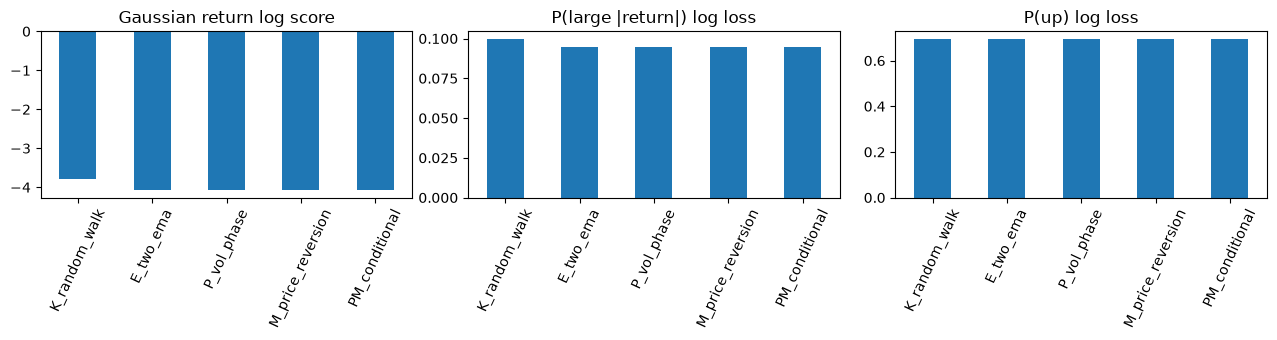

These charts summarize score differences, not standalone significance tests.


In [6]:
primary=scores[scores.horizon_min==vd.PRIMARY].set_index('model')
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
for ax,key,ylab in zip(axes,['nll','tail_logloss','sign_logloss'],
             ['Gaussian return log score','P(large |return|) log loss','P(up) log loss']):
    primary[key].plot(kind='bar',ax=ax,rot=65)
    ax.set_title(ylab)
    ax.set_xlabel('')
plt.tight_layout();plt.show()
print('These charts summarize score differences, not standalone significance tests.')


## 6. Compact run manifest

In [7]:
manifest={'module':'Volatility_Dynamics_13','version':vd.VERSION,
          'registration':vd.registration(),'historical_source':str(HIST_DIR),
          'assets':sorted(panel.underlying.unique()),'excluded_assets':excluded,
          'date_first':str(panel.state_time.min()),'date_last':str(panel.state_time.max()),
          'rows':int(len(panel)),
          'split_days':{str(k):int(v) for k,v in frame.groupby('split').date.nunique().items()},
          'thresholds_train_only':thresholds,
          'scores_output':'13_scores.csv',
          'bootstrap_output':'13_paired_day_bootstrap.csv',
          'decision':decision,
          'source_warning':'Binance spot close history, not RS Binance USD-M perpetual series',
          'no_trading_claim':True}
(OUT/'13_run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Saved compact results in',OUT)
print('No predictions, large tensors or chart PNGs were written.')


Saved compact results in D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\13
No predictions, large tensors or chart PNGs were written.
